In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/bigdata/hotel_bookings.csv')
df.sample(10)

,hotel,lead_time,arrival_month,adults,children,babies,country,market_segment,deposit_type,customer_type,adr,previous_cancellations,special_requests,is_canceled
62,Resort Hotel,12,May,1,2.0,0,JPN,Agent,Non Refund,Group,340.0,2,4,1
273,City Hotel,234,Jan,3,0.0,0,FRA,Agent,Refundable,Group,121.0,0,1,1
173,City Hotel,95,Dec,2,0.0,0,JPN,Online,No Deposit,Contract,256.0,2,1,1
416,Resort Hotel,22,Jul,2,0.0,0,JPN,Agent,Refundable,Group,233.0,1,0,0
269,Resort Hotel,132,Mar,1,1.0,0,KOR,Online,No Deposit,Group,319.0,0,3,1
167,Resort Hotel,99,May,1,0.0,0,KOR,Agent,Non Refund,Contract,342.0,5,4,0
445,Resort Hotel,250,Nov,2,0.0,0,GBR,Corporate,Refundable,Transient,230.0,3,3,1
50,Resort Hotel,126,Mar,2,2.0,1,CHN,Corporate,Non Refund,Transient,325.0,4,3,0
197,City Hotel,284,Apr,3,1.0,0,FRA,Agent,No Deposit,Transient,345.0,1,2,1
194,Resort Hotel,329,Mar,2,0.0,0,USA,Offline,Non Refund,Transient,133.0,5,1,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 457 entries, 0 to 456
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   hotel                   457 non-null    object 
 1   lead_time               457 non-null    int64  
 2   arrival_month           457 non-null    object 
 3   adults                  457 non-null    int64  
 4   children                449 non-null    float64
 5   babies                  457 non-null    int64  
 6   country                 450 non-null    object 
 7   market_segment          457 non-null    object 
 8   deposit_type            453 non-null    object 
 9   customer_type           457 non-null    object 
 10  adr                     452 non-null    float64
 11  previous_cancellations  457 non-null    int64  
 12  special_requests        457 non-null    int64  
 13  is_canceled             457 non-null    int64  
dtypes: float64(2), int64(6), object(6)
memory 

In [ ]:
df.describe()

,lead_time,adults,children,babies,adr,previous_cancellations,special_requests,is_canceled
count,457.000000,457.000000,449.000000,457.000000,452.000000,457.000000,457.000000,457.000000
mean,181.516411,2.317287,0.389755,0.045952,229.280973,2.595186,2.048140,0.660832
std,131.235593,1.364488,0.669476,0.209610,270.274359,1.679409,1.385182,0.473946
min,0.000000,1.000000,0.000000,0.000000,-50.000000,0.000000,0.000000,0.000000
25%,95.000000,2.000000,0.000000,0.000000,143.000000,1.000000,1.000000,0.000000
50%,176.000000,2.000000,0.000000,0.000000,225.000000,3.000000,2.000000,1.000000
75%,258.000000,3.000000,1.000000,0.000000,281.250000,4.000000,3.000000,1.000000
max,1500.000000,20.000000,2.000000,1.000000,5000.000000,5.000000,4.000000,1.000000


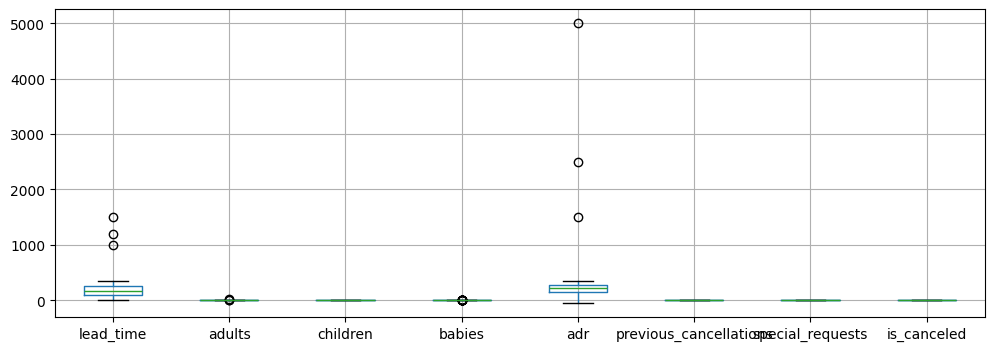

In [10]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,4))
df2 = df.drop(columns=['lead_time', 'adr'])
df.boxplot()
#df2.boxplot()
plt.show()

In [11]:
df3 = df[df["adults"] == 20] # 개별 고객이 성인 20명은 이상치로 판단
df3

,hotel,lead_time,arrival_month,adults,children,babies,country,market_segment,deposit_type,customer_type,adr,previous_cancellations,special_requests,is_canceled
83,City Hotel,149,Jan,20,1.0,0,KOR,Corporate,Non Refund,Transient,202.0,3,2,0


In [12]:
# 결측치 제거
print(df.shape)
df = df.dropna(subset=['children'])
df = df.dropna(subset=['country'])
df = df.dropna(subset=['deposit_type'])
df = df.dropna(subset=['adr'])
print(df.shape)
#df.info()

(457, 14)
(433, 14)


In [13]:
# 이상치 제거 : adults == 20 케이스는 후보로 둠
# lead_time: 0~350, adr : 50~350 벗어나는 값은 삭제
df = df[(df["lead_time"] >= 0) & (df["lead_time"] <= 350) & (df["adr"] >= 50) & (df["adr"] <= 350)]

In [14]:
df.describe()

,lead_time,adults,children,babies,adr,previous_cancellations,special_requests,is_canceled
count,426.000000,426.000000,426.000000,426.000000,426.000000,426.000000,426.000000,426.000000
mean,176.152582,2.281690,0.399061,0.049296,211.612676,2.610329,2.039906,0.673709
std,97.947033,1.252008,0.675904,0.216739,84.100851,1.658713,1.375689,0.469406
min,0.000000,1.000000,0.000000,0.000000,50.000000,0.000000,0.000000,0.000000
25%,95.000000,2.000000,0.000000,0.000000,143.250000,1.000000,1.000000,0.000000
50%,177.000000,2.000000,0.000000,0.000000,224.500000,3.000000,2.000000,1.000000
75%,256.750000,3.000000,1.000000,0.000000,279.750000,4.000000,3.000000,1.000000
max,349.000000,20.000000,2.000000,1.000000,348.000000,5.000000,4.000000,1.000000


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 426 entries, 0 to 456
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   hotel                   426 non-null    object 
 1   lead_time               426 non-null    int64  
 2   arrival_month           426 non-null    object 
 3   adults                  426 non-null    int64  
 4   children                426 non-null    float64
 5   babies                  426 non-null    int64  
 6   country                 426 non-null    object 
 7   market_segment          426 non-null    object 
 8   deposit_type            426 non-null    object 
 9   customer_type           426 non-null    object 
 10  adr                     426 non-null    float64
 11  previous_cancellations  426 non-null    int64  
 12  special_requests        426 non-null    int64  
 13  is_canceled             426 non-null    int64  
dtypes: float64(2), int64(6), object(6)
memory usage

In [16]:
df["country"].unique()

array(['KOR', 'GBR', 'FRA', 'JPN', 'USA', 'CHN'], dtype=object)

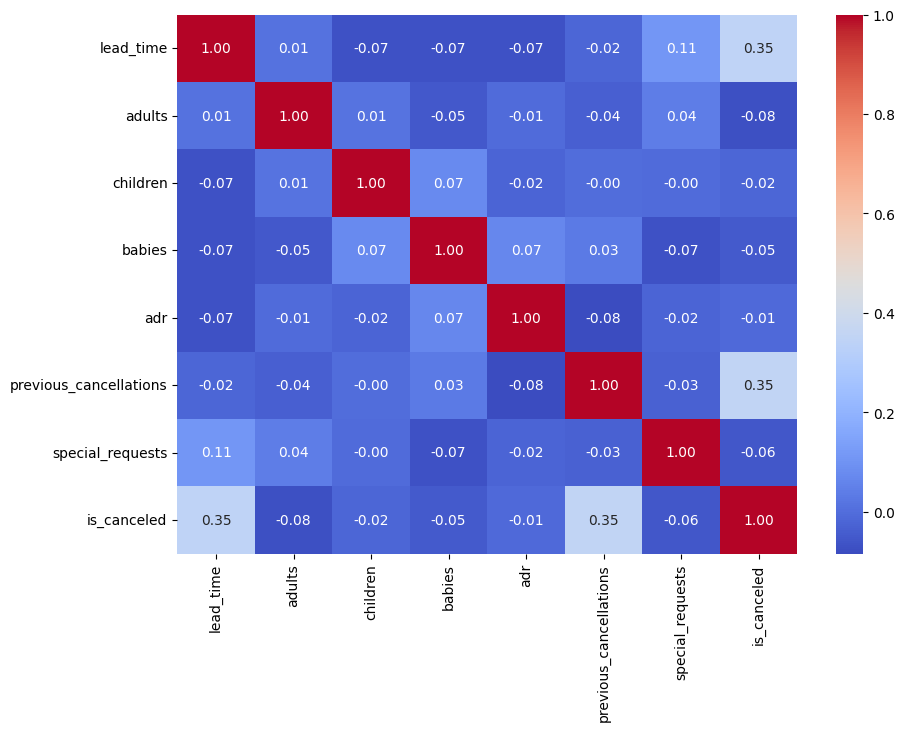

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.show()

In [18]:
X = df.drop(columns=['is_canceled'])
y = df['is_canceled']

In [19]:
# 데이터 분리
from sklearn.model_selection import train_test_split
train_input, test_input, train_target, test_target = train_test_split(X, y, random_state = 42, test_size = 0.3, stratify = y)
print(train_input.shape, test_input.shape, train_target.shape, test_target.shape)

(298, 13) (128, 13) (298,) (128,)


In [20]:
from sklearn.preprocessing import LabelEncoder

train_input = train_input.copy()
test_input = test_input.copy()

columns = [
    "hotel",
    "arrival_month",
    "country",
    "market_segment",
    "deposit_type",
    "customer_type",
]

for col in columns:
  le = LabelEncoder()
  # train_input으로 학습 및 변환
  train_input[col] = le.fit_transform(train_input[col])
  # test_input에 동일 인코더 적용 (학습되지 않은 값 처리를 위해 예외 처리 추가 가능)
  test_input[col] = test_input[col].map(
      lambda s: le.transform([s])[0] if s in le.classes_ else -1
  )

#print(train_input.head())
#print(test_input.head())

In [21]:
# 데이터 표준화
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

# 테스트 데이터로 훈련 데이터 특성이 누수되는 것을 막기 위해 훈련 데이터에만 fit()
train_scaled = scaler.fit_transform(train_input)
test_scaled = scaler.transform(test_input)

### 원핫 인코딩(One-Hot Encoding) 적용하기

앞서 분리한 `train_input`과 `test_input`에 원핫 인코딩을 적용합니다.
여기서는 `scikit-learn`의 `OneHotEncoder`를 사용하여 데이터 누수를 방지하면서 안전하게 인코딩과 표준화를 진행하겠습니다.

In [22]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
import pandas as pd
import numpy as np

# 원본 X, y 분리 직후의 데이터 상태에서 다시 작업하기 위해 데이터를 재준비합니다.
# (LabelEncoder가 적용되지 않은 순수 분리 상태의 복사본 활용)
train_input, test_input, train_target, test_target = train_test_split(
    X, y, random_state=42, test_size=0.3, stratify=y
)

# 범주형 변수 목록
categorical_cols = [
    "hotel",
    "arrival_month",
    "country",
    "market_segment",
    "deposit_type",
    "customer_type",
]

# 수치형 변수 목록
numeric_cols = [col for col in train_input.columns if col not in categorical_cols]

# OneHotEncoder 정의 (훈련 데이터에 없는 범주가 테스트에 등장할 경우 0으로 처리하도록 handle_unknown='ignore' 설정)
oh_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# ColumnTransformer를 활용하여 범주형 변수만 원핫 인코딩 적용
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', oh_encoder, categorical_cols),
        ('num', 'passthrough', numeric_cols)
    ]
)

# 훈련 데이터로 규칙을 학습(fit)하고 변환(transform)
train_encoded = preprocessor.fit_transform(train_input)
test_encoded = preprocessor.transform(test_input)

# 변환된 결과의 특성(Feature) 이름 추출
encoded_cols = list(preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols)) + numeric_cols

# DataFrame 형태로 복원하여 확인
train_encoded_df = pd.DataFrame(train_encoded, columns=encoded_cols)
test_encoded_df = pd.DataFrame(test_encoded, columns=encoded_cols)

print("원핫 인코딩 후 train_encoded_df 크기:", train_encoded_df.shape)
display(train_encoded_df.head())


원핫 인코딩 후 train_encoded_df 크기: (298, 37)


,hotel_City Hotel,hotel_Resort Hotel,arrival_month_Apr,arrival_month_Aug,arrival_month_Dec,arrival_month_Feb,arrival_month_Jan,arrival_month_Jul,arrival_month_Jun,arrival_month_Mar,...,customer_type_Contract,customer_type_Group,customer_type_Transient,lead_time,adults,children,babies,adr,previous_cancellations,special_requests
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,189.0,2.0,0.0,0.0,177.0,2.0,2.0
1,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,249.0,1.0,0.0,0.0,168.0,5.0,3.0
2,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,347.0,3.0,0.0,0.0,299.0,0.0,4.0
3,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,191.0,3.0,2.0,0.0,205.0,4.0,3.0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,291.0,3.0,0.0,0.0,239.0,2.0,2.0


### 인코딩 완료 후 피처 표준화(Standard Scaling)

원핫 인코딩이 완료되어 모든 피처가 수치형으로 변환되었으므로, 최종적으로 `StandardScaler`를 적용하여 스케일을 맞춰줍니다.

In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# 훈련 데이터 세트로만 fit을 수행한 후 변환
train_scaled = scaler.fit_transform(train_encoded_df)
test_scaled = scaler.transform(test_encoded_df)

print("최종 훈련 세트 스케일링 완료 형태:", train_scaled.shape)
print("최종 테스트 세트 스케일링 완료 형태:", test_scaled.shape)


최종 훈련 세트 스케일링 완료 형태: (298, 37)
최종 테스트 세트 스케일링 완료 형태: (128, 37)


<Figure size 600x600 with 0 Axes>

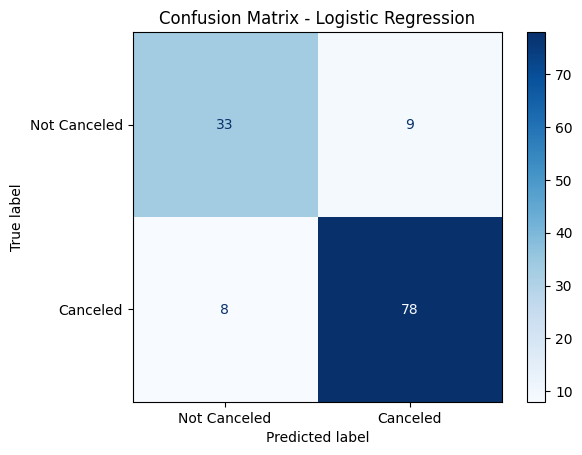

정확도 : 0.8671875
정밀도 : 0.896551724137931
재현율 : 0.9069767441860465
특이도 : 0.7857142857142857


In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. 로지스틱 회귀 모델 생성 및 학습
lr = LogisticRegression(random_state=42)
lr.fit(train_scaled, train_target)

# 2. 혼돈 행렬 시각화
plt.figure(figsize=(6, 6))
ConfusionMatrixDisplay.from_estimator(
    lr,
    test_scaled,
    test_target,
    cmap='Blues',
    display_labels=['Not Canceled', 'Canceled']
)
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

tp = 78; fp = 9; fn = 8; tn = 33
print("정확도 :", (tp+tn)/(tp+fp+fn+tn))
print("정밀도 :", tp/(tp+fp))
print("재현율 :", tp/(tp+fn))
print("특이도 :", tn/(tn+fp))

In [27]:
# DecisionTreeClassifier
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(
    #max_depth = 6,
    random_state = 42
)
dt.fit(train_scaled, train_target)
print(dt.score(train_scaled, train_target))
print(dt.score(test_scaled, test_target))

1.0
0.9921875


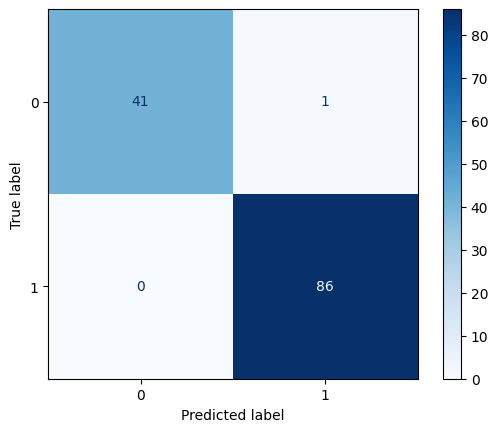

정확도 : 0.9921875
정밀도 : 0.9885057471264368
재현율 : 1.0
특이도 : 0.9761904761904762


In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(
    dt,
    test_scaled, test_target,
    cmap = 'Blues'
)
plt.show()

tp = 86; fp = 1; fn = 0; tn = 41
print("정확도 :", (tp+tn)/(tp+fp+fn+tn))
print("정밀도 :", tp/(tp+fp))
print("재현율 :", tp/(tp+fn))
print("특이도 :", tn/(tn+fp))